# Imports

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform

rng = np.random.default_rng(1)

N, K, T = 24, 4, 100                      # število vrst, skupin in točk
f_skupine = [0.02, 0.035, 0.05, 0.08]     # frekvence skupin [cikli na vzorec]

# Funkcije

In [2]:
def generiraj(N, K, T, faza=True, rng=rng):
    """N sinusnih časovnih vrst dolžine T v K skupinah. Znotraj skupine: frekvenca +-5 %,
    amplituda 0.5-1, (naključna faza), šum 10 % amplitude. Vrne (X, oznake skupin)."""
    t = np.arange(T)
    X, skup = np.zeros((N, T)), np.arange(N) % K
    for i in range(N):
        f = f_skupine[skup[i]] * (1 + rng.uniform(-0.05, 0.05))
        A = rng.uniform(0.5, 1.0)
        fi = rng.uniform(0, 2 * np.pi) if faza else 0.0
        X[i] = A * np.sin(2 * np.pi * f * t + fi) + rng.normal(0, 0.1 * A, T)
    return X, skup


def razdalja_evklid(x, y):
    return np.sqrt(np.sum((x - y)**2))


def razdalja_korelacija(x, y):
    """1 - r, kjer je r Pearsonov korelacijski koeficient."""
    dx, dy = x - x.mean(), y - y.mean()
    return 1 - np.sum(dx * dy) / np.sqrt(np.sum(dx**2) * np.sum(dy**2))


def razdalja_dtw(x, y, w=None):
    """Razdalja DTW s ceno |x_i - y_j| in (neobvezno) oknom Sakoe-Chiba širine w."""
    n, m = len(x), len(y)
    w = max(w, abs(n - m)) if w is not None else max(n, m)
    D = np.full((n + 1, m + 1), np.inf)
    D[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(max(1, i - w), min(m, i + w) + 1):
            D[i, j] = abs(x[i - 1] - y[j - 1]) + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return D[n, m]


def razdalja_spekter(x, y):
    """Evklidska razdalja med normiranima amplitudnima spektroma (neodvisna od faze in amplitude)."""
    Sx, Sy = np.abs(np.fft.rfft(x - x.mean())), np.abs(np.fft.rfft(y - y.mean()))
    return np.linalg.norm(Sx / np.linalg.norm(Sx) - Sy / np.linalg.norm(Sy))


def matrika_razdalj(X, razdalja, **kw):
    n = len(X)
    D = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            D[i, j] = D[j, i] = razdalja(X[i], X[j], **kw)
    return D


def grupiraj(D, K):
    """Hierarhično grupiranje (povprečna povezava) v K skupin. Vrne (oznake, povezovalna matrika)."""
    Z = linkage(squareform(D, checks=False), method="average")
    return fcluster(Z, K, criterion="maxclust"), Z


def cistost(oznake, resnica):
    """Delež vrst, ki pripadajo prevladujoči pravi skupini svoje gruče."""
    return sum(np.bincount(resnica[oznake == c]).max() for c in np.unique(oznake)) / len(resnica)

# Testno območje

In [3]:
# P1, P2: dve sinusoidi z zamikom faze
t = np.arange(1000)
for fi in (0, np.pi / 2, np.pi):
    x, y = np.sin(0.05 * t), np.sin(0.05 * t + fi)
    print(f"fi = {fi:.2f}: D_E^2 / T = {razdalja_evklid(x, y)**2 / len(t):.3f}, r = {1 - razdalja_korelacija(x, y):.3f}")
# P3: DTW na roke
print("P3: DTW =", razdalja_dtw(np.array([0, 1, 2, 3.]), np.array([0, 0, 1, 2.])),
      " L1 =", np.abs(np.array([0, 1, 2, 3.]) - np.array([0, 0, 1, 2.])).sum())
# P4: čistost
print("čistost:", cistost(np.array([1, 1, 2, 2, 2, 3]), np.array([0, 0, 0, 1, 1, 2])))

fi = 0.00: D_E^2 / T = 0.000, r = 1.000
fi = 1.57: D_E^2 / T = 0.998, r = 0.002
fi = 3.14: D_E^2 / T = 2.010, r = -1.000
P3: DTW = 1.0  L1 = 3.0
čistost: 0.8333333333333334


# Naloga 1 - Slika 2

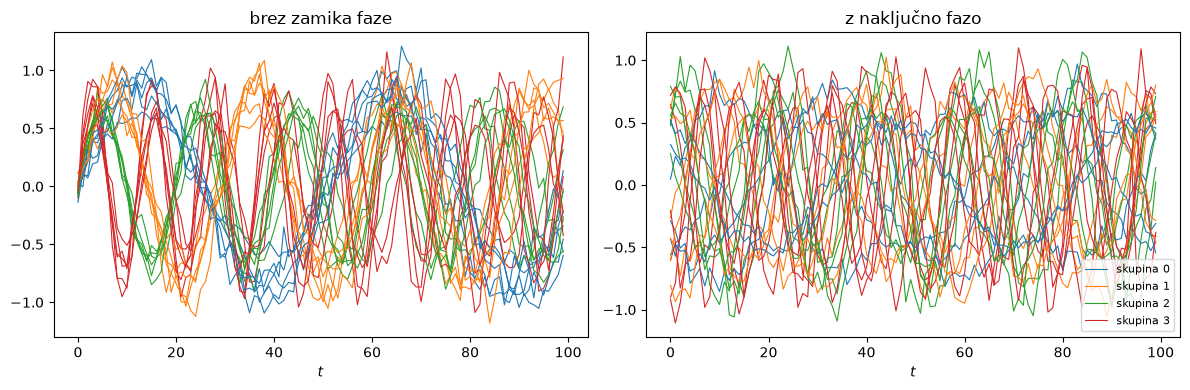

In [4]:
X0, skup = generiraj(N, K, T, faza=False)
X, _ = generiraj(N, K, T, faza=True)
barve = plt.cm.tab10(np.arange(K))
fig = plt.figure(figsize=(12, 4))
for k, (Y, naslov) in enumerate(((X0, "brez zamika faze"), (X, "z naključno fazo"))):
    ax = fig.add_subplot(1, 2, k + 1)
    for i in range(N):
        ax.plot(Y[i], color=barve[skup[i]], lw=0.8, label=f"skupina {skup[i]}" if i < K else None)
    ax.set_title(naslov)
    ax.set_xlabel("$t$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Naloga 2 - Slika 3

evklidska   : čas = 0.00 s
korelacijska: čas = 0.01 s
DTW         : čas = 0.92 s
spekter     : čas = 0.02 s


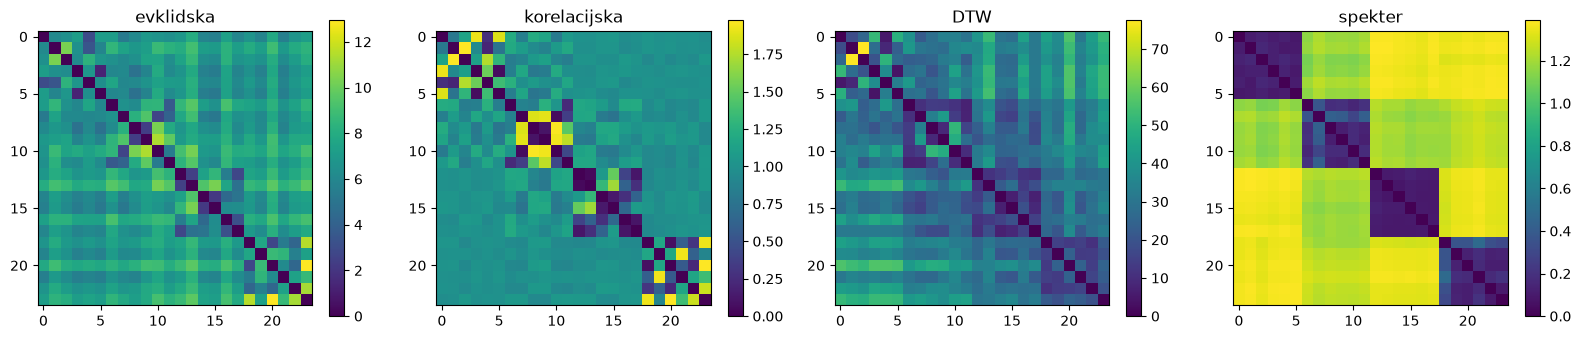

In [5]:
razdalje = {"evklidska": (razdalja_evklid, {}), "korelacijska": (razdalja_korelacija, {}),
            "DTW": (razdalja_dtw, {"w": 10}), "spekter": (razdalja_spekter, {})}
red = np.argsort(skup, kind="stable")          # vrste uredimo po skupinah
matrike = {}
fig = plt.figure(figsize=(16, 4))
for k, (ime, (fn, kw)) in enumerate(razdalje.items()):
    t0 = time.time()
    matrike[ime] = matrika_razdalj(X, fn, **kw)
    print(f"{ime:12s}: čas = {time.time() - t0:.2f} s")
    ax = fig.add_subplot(1, 4, k + 1)
    im = ax.imshow(matrike[ime][np.ix_(red, red)], cmap="viridis")
    ax.set_title(ime)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

# Naloga 3 - Slika 4

evklidska   : čistost = 0.58
korelacijska: čistost = 0.54
DTW         : čistost = 0.75
spekter     : čistost = 1.00


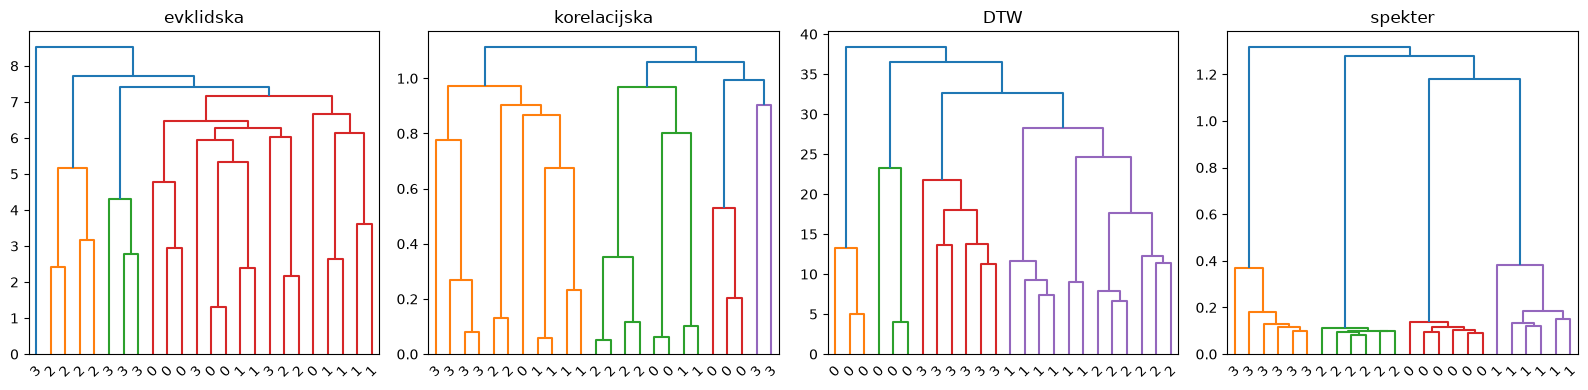

In [6]:
fig = plt.figure(figsize=(16, 4))
for k, (ime, D) in enumerate(matrike.items()):
    oznake, Z = grupiraj(D, K)
    print(f"{ime:12s}: čistost = {cistost(oznake, skup):.2f}")
    ax = fig.add_subplot(1, 4, k + 1)
    dendrogram(Z, ax=ax, labels=skup, color_threshold=Z[-K + 1, 2])
    ax.set_title(ime)
fig.tight_layout()
plt.show()

# Naloga 4

In [7]:
for faza in (False, True):
    rez = {ime: [] for ime in razdalje}
    for p in range(5):
        Xp, sp = generiraj(N, K, T, faza=faza, rng=np.random.default_rng(100 + p))
        for ime, (fn, kw) in razdalje.items():
            rez[ime].append(cistost(grupiraj(matrika_razdalj(Xp, fn, **kw), K)[0], sp))
    print(f"faza = {faza!s:5}: " + ", ".join(f"{ime} = {np.mean(v):.2f}" for ime, v in rez.items()))

faza = False: evklidska = 0.96, korelacijska = 0.95, DTW = 0.97, spekter = 1.00
faza = True : evklidska = 0.52, korelacijska = 0.54, DTW = 0.73, spekter = 1.00
